# Figure 1 — Toffoli at $L=12$ and $L=120$

Five optimisers on the same problem, against iteration count and against wall
clock, at two initial spreads. Everything shared with the other figures —
the model, the timing harness, the per-seed cache, the drawing helpers — is in
`common.py`.

In [1]:
from common import *


---

# Figure 1 — Toffoli at $L=12$ and $L=120$

Four methods on the same problem: the three Newton rules that differ only in how
they regularise a singular Hessian, and GEOPE with an Armijo line search.

Counted in **iterations** (panels a, c) they are broadly comparable, which is
the reading a referee gets from an iteration-axis plot. Counted in **wall
clock** (panels b, d) they are not, and the gap opens with the pulse length: at
$L=120$ the Hessian is $1080\times1080$, RFO's `condition_loop` re-diagonalises
it until the condition number is under $\kappa$, and GEOPE never forms it at
all.

In [ ]:
N_RUNS = 100
#: (L, title of the iteration panel, title of the wall-clock panel)
CASES = [
    (12, r"(a) Toffoli, $L=12$", r"(b) $L=12$, wall clock"),
    (120, r"(c) Toffoli, $L=120$", r"(d) $L=120$, wall clock"),
]
METHODS = {
    "GEOPE": Armijo(),
    "LBFGS": LBFGS(memory=100),
    "NewtonTRM": NewtonTRM(delta=1e-3),
    "NewtonRFO": NewtonRFO(kappa=10**6),
    "NewtonSaddleFree": NewtonSaddleFree(),
}


def fig1_config(steps, method, config, spread=SPREAD):
    """Everything that changes this block's numbers.

    The spread is in the *tag* as well as in the config, so a block is
    identifiable on disk without opening its sidecar.
    """
    cfg = {
        "tag": f"fig1_CCX_L{steps}_{spread_slug(spread)}_{method}",
        "kind": "fig1-toffoli-iterations-walltime",
        "gate": "CCX",
        "steps": steps,
        "method": method,
        "config": repr(config),
        "spread": spread,
        "n_qubits": 3,
        "max_steps": MAX_STEPS,
        "precision": PRECISION,
    }
    if method == "GEOPE":
        cfg["geope_max_step"] = GEOPE_MAX_STEP
    return cfg


def fig1_sweep(n_runs=None, force=False, spread=SPREAD):
    """Every ``(L, method)`` block at one spread, keyed ``(steps, method)``."""
    n_runs = N_RUNS if n_runs is None else n_runs
    blocks = {}
    for steps, _iter_title, _time_title in CASES:
        for method, config in METHODS.items():

            def build(steps=steps, method=method, config=config):
                params = make_parameters(3, steps, "CCX", spread=spread)
                optimiser = (
                    Geope(params, history=History())
                    if method == "GEOPE"
                    else Grape(params, precision=PRECISION, history=History())
                )
                return params, optimiser, config

            blocks[(steps, method)] = run_block(
                fig1_config(steps, method, config, spread),
                build,
                n_runs,
                spread=spread,
                force=force,
            )
    return blocks


fig1_blocks = fig1_sweep()

  fig1_CCX_L12_spread0p01pi_GEOPE          100/100 converged  median   0.09s   cached (100 stored)
  fig1_CCX_L12_spread0p01pi_LBFGS          computing seeds 0-99 of 100
    seed 0/99      0.1s   76 steps  1-F 7.1e-10
    seed 1/99      0.1s   81 steps  1-F 9.8e-10
    seed 2/99      0.1s   87 steps  1-F 7.9e-10
    seed 3/99      0.1s   90 steps  1-F 9.2e-10
    seed 4/99      0.2s  101 steps  1-F 6.3e-10
    seed 5/99      0.2s   88 steps  1-F 8.2e-10
    seed 6/99      0.2s  102 steps  1-F 7.7e-10
    seed 7/99      0.2s   93 steps  1-F 9.9e-10
    seed 8/99      0.2s  110 steps  1-F 3.9e-10
    seed 9/99      0.2s   93 steps  1-F 4.3e-10
    seed 10/99      0.2s   96 steps  1-F 6.8e-10
    seed 11/99      0.1s   99 steps  1-F 4.4e-10
    seed 12/99      0.1s   83 steps  1-F 9.0e-10
    seed 13/99      0.1s   95 steps  1-F 9.7e-10
    seed 14/99      0.1s   86 steps  1-F 9.3e-10
    seed 15/99      0.1s   86 steps  1-F 7.9e-10
    seed 16/99      0.1s   92 steps  1-F 1.0e-09
    see

### Combined figure

The same four methods at **two initial spreads**, because which one you start
from changes the ranking and not just the margin. At $1.0\pi$ the pulse starts
far from the target and every method spends its budget on the descent; at
$0.01\pi$ it starts near the identity, where the Hessian is singular in the
directions that matter and the Newton rules pay for it — RFO's `condition_loop`
re-diagonalises a $1080\times1080$ matrix until $\kappa$ is met, so a single
$L=120$ run takes over an hour and still exits on `max_steps`.

Panels **a, b** are the near-identity start, **c, d** the random one; within
each row the left sub-plot counts iterations and the right one wall clock.

  fig1_CCX_L12_spread1pi_GEOPE             100/100 converged  median   0.08s   cached (100 stored)
  fig1_CCX_L12_spread1pi_LBFGS             100/100 converged  median   0.06s   cached (100 stored)
  fig1_CCX_L12_spread1pi_NewtonTRM         100/100 converged  median   0.10s   cached (100 stored)
  fig1_CCX_L12_spread1pi_NewtonRFO         100/100 converged  median   0.13s   cached (100 stored)
  fig1_CCX_L12_spread1pi_NewtonSaddleFree  100/100 converged  median   0.12s   cached (100 stored)
  fig1_CCX_L120_spread1pi_GEOPE            100/100 converged  median   0.18s   cached (100 stored)
  fig1_CCX_L120_spread1pi_LBFGS            100/100 converged  median   0.11s   cached (100 stored)
  fig1_CCX_L120_spread1pi_NewtonTRM        100/100 converged  median   3.71s   cached (100 stored)
  fig1_CCX_L120_spread1pi_NewtonRFO        100/100 converged  median  13.68s   cached (100 stored)
  fig1_CCX_L120_spread1pi_NewtonSaddleFree 100/100 converged  median   3.98s   cached (100 stored)
figures/fi

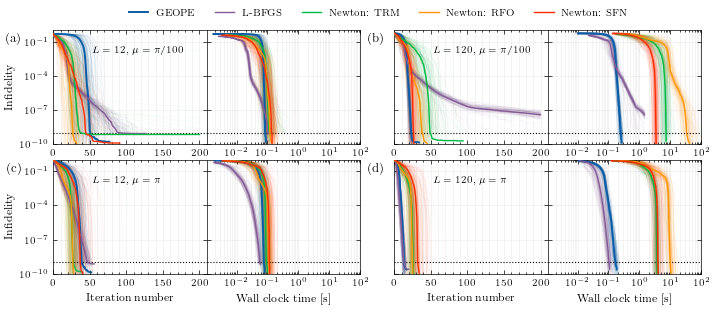

In [ ]:
#: One row per initial spread, top first, with the panel letters that row
#: carries.
SPREAD_ROWS = [(0.01, "ab", "\pi/100"), (1.0, "cd", "\pi")]
#: The row at the notebook-wide `SPREAD` is the one the figure above already
#: read, so take it rather than re-reading it -- which also makes it explicit
#: that the two figures are showing the same numbers. The other row is a cache
#: read of its own; both sweeps are on disk, so neither touches JAX.
fig1_by_spread = {
    spread: fig1_blocks if spread == SPREAD else fig1_sweep(spread=spread)
    for spread, _letters, _pi_label in SPREAD_ROWS
}

fig = plt.figure(figsize=(TWO_COLUMN, 2.9))
gs = fig.add_gridspec(2, 5, width_ratios=[1, 1, 0.22, 1, 1], wspace=0.0, hspace=0.14)
first = fig.add_subplot(gs[0, 0])
axes = {
    (row, col): (
        first if (row, col) == (0, 0) else fig.add_subplot(gs[row, col], sharey=first)
    )
    for row in (0, 1)
    for col in (0, 1, 3, 4)
}

for row, (spread, letters, pi_label) in enumerate(SPREAD_ROWS):
    sweep = fig1_by_spread[spread]
    pairs = ((axes[row, 0], axes[row, 1]), (axes[row, 3], axes[row, 4]))
    for col, (
        (steps, _iter_title, _time_title),
        (ax_iter, ax_time),
        letter,
    ) in enumerate(zip(CASES, pairs, letters)):
        blocks = {m: sweep[(steps, m)] for m in METHODS}
        draw_iterations(ax_iter, blocks, METHODS)
        draw_walltime(ax_time, blocks, METHODS)
        finish(ax_iter, "")
        finish(ax_time, "")
        # ax_iter.xaxis.set_major_locator(MaxNLocator(4, prune="upper"))
        ax_iter.text(
            -0.06 + (col - 1) * 0.14,
            0.98,
            rf"({letter})",
            transform=ax_iter.transAxes,
            ha="right",
            va="top",
            fontsize=PANEL_LABEL_SIZE,
            zorder=5,
            bbox=dict(facecolor="white", edgecolor="none", alpha=0.85, pad=1.2),
        )

        ax_iter.text(
            0.25,
            0.8,
            rf"$L={steps}$, $\mu={pi_label}$",
            transform=ax_iter.transAxes,
            fontsize=ANNOTATION_SIZE,
            zorder=5,
        )
        # ax_iter.set_title(rf"$L={steps}$, spread = {spread:1.2f}$\pi$", x=1.0)
        ax_iter.set_xlim(0, 210)
        ax_time.set_xlim(1.1e-3, 1e2)


# One y-axis per merged panel: only the far-left sub-plot of a row keeps its
# labels.
for (row, col), ax in axes.items():
    if col != 0:
        ax.tick_params(labelleft=False)
    else:
        ax.set_ylabel(r"Infidelity")
    if row == 0:
        ax.set_xlabel("")
        # ax.set_xticks([])

# One legend under all eight sub-plots: in-axes it would sit on top of the very
# curves it names, since every trajectory ends in the lower-left corner.
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    loc="lower center",
    ncol=5,
    frameon=False,
    bbox_to_anchor=(0.53, 1.0),
)
# Explicit margins rather than `tight_layout`, which recomputes `wspace` and
# would prise the merged pairs apart again.
fig.subplots_adjust(left=0.072, right=0.985, top=0.985, bottom=0.145, wspace=0.0)
print(
    save_figure(
        fig,
        "fig1_toffoli_"
        + "_".join(spread_slug(s) for s, _letters, _pi_label in SPREAD_ROWS),
    )
)
plt.show()